# Task 3
The previous problem should next be adjusted to include a constraint on the
exact number of items that need to be selected for the knapsack (e.g., each
individual has exactly 10 items, not more, not less). Assume that no population
member or offspring may violate the constraint on the exact number of items.
The following tasks should be considered:

## Setup

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)

# loading Data
df = pd.read_csv('../data/data_1001.csv')
item_values = df["Value"].to_list()
item_weights = df["Weight"].to_list()


# Loading test data
test_df = pd.read_csv('../data/data_31.csv')
test_item_values = test_df["Value"].to_list()
test_item_weights = test_df["Weight"].to_list()


## Functions from Task 1 and Task 2

### Task 1 functions (that did not need to be fixed)

In [2]:
# Survivor Selection Function:
# (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring;
# Outputs: (New) population). 
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]] 

### Task 2 functions (that did not need to be fixed)

In [3]:
# using dotproduct to find fitness
def fitness (individuals: list[list[int]], values: list[int]) -> list[int]:
    """
    Calculate the fitness of each individual in the population.

    An individual's fitness is the total value of the items it selects,
    computed as the dot product of its genes and the item values.

    Args:
        individuals: list of individuals in the population
        values: list of item values
    
    Returns:
        A list with one fitness score per individual.
    
    Example:
        >>> fitness([[0,1,1],[1,1,0]], [200,100,50])
        [150, 300]
    """
    #value_list = [None] * len(individuals)
    
    #for index in range(len(individuals)):
    #    value_list[index] = np.dot(individuals[index], values)
    #
    #return value_list

    return (np.array(individuals) @ np.array(values)).tolist()


def simple_genetic_algorithm(
    population_size, number_iter,
    crossover_prob, mutation_prob,
    value_list
    ) -> tuple[list[float], list[float], list[list[int], list[float]]]:
    """
    SGA for Task 2

    Returns:
        A list with 4 items.
        * avg_fitness_data
        * best_fitness_data
        * population
        * fitness_values
    """
    # To keep track of avg and best fitness across iterations
    avg_fitness_data, best_fitness_data = [], []
    # curr_avg_fit, curr_best_fit = 0.0, 0.0
    
    gene_len = len(value_list)
    population = initialization_knapsack(
        pop_size=population_size,
        num_bits=gene_len
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, value_list)


        new_avg_fitness = np.mean(fitness_values)
        avg_fitness_data.append(new_avg_fitness)

        new_best_fitness = np.max(fitness_values)
        best_fitness_data.append(new_best_fitness)

        # if new_best_fitness > curr_best_fit:
        #    curr_best_fit = new_best_fitness

        parents = parent_selection(population, fitness_values)

        offspring = one_point_crossover(parents, crossover_prob)
        offspring = mutation(offspring, mutation_prob)
        offspring_fitness_values = fitness(offspring, value_list)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return avg_fitness_data, best_fitness_data, population, fitness(population, value_list)

### Test helper functions / random functions

In [5]:
def test_structure(population: list[int]):
    print("Printing Individuals")
    print(f"num{"":>5}| {"0 count":<} | {"1 count":<} | only (1/0) | {"Item indexes":<41} | ")
    for num, ind in enumerate(population):
        ones  = ind.count(1)
        zeros = ind.count(0)
        only_binary = (ones + zeros == len(ind))

        arr_individual = np.array(ind)
        selected_positions   = np.where(arr_individual == 1)[0]

        print(f"{num+1:<8}| {zeros:<7} | {ones:<7} | {only_binary:<10} | {selected_positions} | ")
    
    print()
    all_binary = all(ind.count(0) + ind.count(1) == len(ind) for ind in population)
    print(f"All individuals contain only 0s and 1s: {all_binary}")


def show_population_weight():
    """
    print population with weight
    """
    return


def plot_value_against_weight(population: list[list], values:list, weights: list):
    #individual = np.array(population[0])
    values = np.array(values)
    weights = np.array(weights)
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    colors = plt.cm.tab20(np.linspace(0, 1, len(population)))

    plt.figure(figsize=(10, 7))
    for i, individual in enumerate(population):
        mask = np.array(individual) == 1
        selected_values = weights[mask]
        selected_weights = values[mask]
        plt.scatter(
            selected_values, selected_weights,
            s=10, alpha=0.6,
            color=colors[i],
            marker=markers[i % len(markers)],
            label=f"Individual {i}"
        )

    plt.xlabel("Item weight")
    plt.ylabel("Item value")
    plt.title("Item value vs Item weight for each individual")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.show()


def plot_avg_value_against_weight(population: list[list], values:list, weights: list):
    #individual = np.array(population[0])
    values = np.array(values)
    weights = np.array(weights)
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    colors = plt.cm.tab20(np.linspace(0, 1, len(population)))

    plt.figure(figsize=(10, 7))
    for i, individual in enumerate(population):
        mask = np.array(individual) == 1
        num_items = mask.sum()
        selected_values = weights[mask].sum() / num_items
        selected_weights = values[mask].sum() / num_items
        plt.scatter(
            selected_values, selected_weights,
            s=10, alpha=0.6,
            color=colors[i],
            marker=markers[i % len(markers)],
            label=f"Individual {i}"
        )

    plt.xlabel("Avg item weight")
    plt.ylabel("Avg item value")
    plt.title("Average item value vs average Item weight for each individual")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.show()

    print(f"")


def plot_generation_avg_value_vs_weight(generations: list, values:list, weights: list):
    #individual = np.array(population[0])
    values = np.array(values)
    weights = np.array(weights)

    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    colors = plt.cm.tab20(np.linspace(0, 1, len(generations)))

    plt.figure(figsize=(10, 7))
    for i, population in enumerate(generations):
        total_value  = 0
        total_weight = 0
        for individual in population:
            mask = np.array(individual) == 1
            num_items = mask.sum()

            value = values[mask].sum() / num_items
            weight = weights[mask].sum() / num_items

            total_value += value
            total_weight += weight


        avg_value  = total_value / len(population)
        avg_weight = total_weight / len(population)

        plt.scatter(
            avg_value, avg_weight,
            s=10, alpha=0.6,
            color=colors[i],
            marker=markers[i % len(markers)],
            label=f"Generation {i}"
        )

    plt.xlabel("Avg item weight")
    plt.ylabel("Avg item value")
    plt.title("Average item value vs average Item weight for each generation")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.show()

### New parent selection
**NOTE:** has a small change where it changes fitness from negative to postive.

In [6]:
# Parent Selection Function: 
# (Inputs: Individuals, Fitness values;
# Output: Parents (in random order, same number as individuals)). 
def parent_selection_task_3( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional parent selection such that more fit parents have a higher probability to be selected. """
    fitness = np.array(fitness_values, dtype=float)

    if fitness.min() < 0:
        fitness = fitness - fitness.min() + 1e-6   # shift so the minimum is just above 0

    if fitness.sum() == 0:
        probs = np.full(len(fitness), 1 / len(fitness))   # all equal: uniform selection
    else:
        probs = fitness / fitness.sum()

    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

## Subtask 1
Discuss which functions of the SGA (i.e., initialization, fitness, parent se-
lection, recombination, mutation, survivor selection) need to be updated
so that the constraint on the exact number of items is not violated by any
population member or offspring. Comment for each whether it needs to
be updated, why the original function version will or may lead to a vio-
lation of the constraint and how it could be updated (Note: Full-point
solutions must satisfy the constraint immediately after recom-
bination and immediately after mutation, without first creating
invalid offspring. Solutions that temporarily create invalid off-
spring e.g., by using bitflip (as in task 2), and subsequently repair
them (e.g., at random or otherwise) are acceptable but will not
receive full points.).

### Written part

#### **Initialization:** 
The initialization functions needs to be updated, since in task to it selects at random about half of the bits to be turned on. This would break the rule of only ever having k bits turned on (k items selected). How to fix: first create the gene list with how ever many items there are, all elements in that list set to **zero**. Then we can use the handy **np.random.choice()** function from numpy with replacements set to false.  **np.random.choice(size_of_gene_list=1001, size=k, replace=False)**, this would select k random indexes in the list we can then set to be a **One**, the replace=False guarantees that the same index can not be selected twice.

#### **Fitness:**
The fitness function does not need to be changed since the only thing it does is calculate the fitness score of an individual, it never changes anything in that individual.

#### **Parent Selection:**
The parent selection function does not need to be changed since the only thing it does is copy the fittest individuals in a given population, so if we can guarantee that all of the individuals in the population have only k items selected, then there is no need to change the parent selection function

#### **Recombination:**
The recombination function does need to changed, since when the recombination function performs 1-point crossover it can break the guarantee that each gene can only have k values e.g., if we cut each parent in the middle, and say each has 5 items on both sides then the guarantee still holds. 

But say with k = 3:.
* Parent A: [0, 0, 0, 1, 1, 1] = 3 items (ok)
* Parent B: [1, 0, 1, 0, 1, 0] = 3 items (ok)

Then we cut after position 2
* Child A: [0, 0 | 1, 0, 1, 0] = 2 items (not ok)
* Child B: [1, 0 | 0, 1, 1, 1] = 4 items (not ok)

How we solve the problem?.
We start by sorting items into one of three groups:
1. Both parents picked item.
2. Only one of them picked that that item.
3. Neither parent picked that item.

How the child picks from those two parents:
* Keeps all items in group 1, since both parent chose it.
* Skips all items in group 3, since neither parent chose it.
* Then the child fills the remaining slots with random picks from group 2.

This guarantees the children of two parents always fulfils the guarantee of exactly k items.

#### **Mutation:**
The mutation function needs to be changed, the function right now goes through the gene list and has some probability to change (bit flip) each entry of gene. That would break the constraint on exactly k number of items, so there needs to be a way to guarantee that when we have a entry flip some other entry in the gene flips the oppsite way e.g., entry number 27 flips from 1 to 0.

The solution we are going with: For each of the k selected items, with probability PM, swap it with a random unselected item. Why go with this solution it? It makes the algorithm run alot, Instead of iterating over each gene of every individual. We simply iterate k times and have PM probability to swap that with a random unselected item.

then the mutation functions needs to make sure that some entry with 0 flips to 1, it does that by randomly selecting a entry that is a zreo. That way we make sure that the the constraint of exactly k items is always fulfilled.


#### **Mutation:**
The mutation function needs to be updated. The original version goes through every gene of an individual and, with probability PM, flips it (0 → 1 or 1 → 0). Each flip changes the number of selected items by one, so after mutation an individual will almost never have exactly k items, which breaks the constraint. To keep the count fixed, every flip from 1 to 0 must be paired with a flip from 0 to 1, e.g. if gene 27 flips from 1 to 0, some other gene that is currently 0 must flip to 1.

**Our solution (swap mutation):** For each of the k selected items, with probability PM, the item is swapped with a randomly chosen unselected item. Each swap removes exactly one item and adds exactly one, so the individual has exactly k selected items after every single swap. No invalid offspring is ever created and no repair step is needed.

**Why this approach:** It mirrors the original bit-flip mutation ("each gene gets a chance to mutate with probability PM"), but only iterates over the k selected genes instead of all genes, which makes it faster, especially for small k. The expected number of swaps per individual is k × PM, so mutation strength grows with k (e.g. = 1 swap for k = 10, = 80 swaps for k = 802 with PM = 0.1).

**Edge case:** When k equals the total number of items (k = 1001), there are no unselected items to swap with, so mutation has no effect. This is expected, since only one valid solution exists in that case.

#### **Survivor Selection:**
The survivor selection function does not need to be changed, for the same reason we don't need to change parent selection function as long as we guarantee a population that follows the constraint it cannot change any gene in the population.

### Fixing the broken functions

#### **Initialization**

In [7]:
def initialization_knapsack_task_3( pop_size: int, gene_len: int, k_items: int) -> list[list[int]]:
    """
    This function creates the individuals for the population, each having gene_len genes. 

    Args:
        pop_size: size of the population.
        gene_len: how long the gene is.
        gene_limit: how many entries in the gene can be 1.
    
    Returns:
      A list of `pop_size` individuals, each a list of `gene_len` ints (0 or 1), 
      with a limit of 1 based on gene_limit.
    
    Example:
        >>> initialization_knapsack(pop_size=3, gene_len=4, gene_limit=1)
        [[0, 1, 0, 0], [1, 0, 0, 0], [0, 1, 0, 0]]
    """
    
    population = []

    for _ in range(pop_size):        
        individual = np.zeros(gene_len, dtype=int) 
        chosen = np.random.choice(gene_len, size=k_items, replace=False)
        individual[chosen] = 1
        
        population.append(individual.tolist())
    
    return population

##### Testing initialization_knapsack_task_3 (TODO: move to subtask 2)

In [8]:
def test_initialization_knapsack_task_3():
    population_size = 5
    gene_len        = len(item_values)
    items_allowed   = 10

    population = initialization_knapsack_task_3(
        pop_size=population_size,
        gene_len=gene_len,
        k_items=items_allowed)

    print("Testing population size: expected 5")
    if len(population) == 5:
        print("CORRECT")
        print("population size: ", len(population))
    else:
        print("INCORRECT")

    print()

    print("Testing individual lenght: expected 1001")
    individual_1 = population[0]
    if len(individual_1) == 1001:
        print("CORRECT")
        print("individual size: ", len(individual_1))
    else:
        print("INCORRECT")
        print("individual size: ", len(individual_1))

    print()

    test_structure(population)

test_initialization_knapsack_task_3()

Testing population size: expected 5
CORRECT
population size:  5

Testing individual lenght: expected 1001
CORRECT
individual size:  1001

Printing Individuals
num     | 0 count | 1 count | only (1/0) | Item indexes                              | 
1       | 991     | 10      | 1          | [ 58 117 161 212 291 439 523 574 842 922] | 
2       | 991     | 10      | 1          | [ 75 122 391 401 575 729 770 849 920 980] | 
3       | 991     | 10      | 1          | [ 88  99 179 203 394 620 712 767 844 942] | 
4       | 991     | 10      | 1          | [139 195 224 297 338 391 520 878 934 997] | 
5       | 991     | 10      | 1          | [ 41 169 471 632 715 718 732 827 840 920] | 

All individuals contain only 0s and 1s: True


#### Recombination

In [9]:
def make_children(parent_a: list[int], parent_b: list[int], k_items) -> tuple[list[int], list[int]]:
    #build child
    arr_parent_1 = np.array(parent_a)
    arr_parent_2 = np.array(parent_b)

    selected_p1 = arr_parent_1 == 1
    selected_p2 = arr_parent_2 == 1

    # Both parents picket the item
    group_1 = selected_p1 & selected_p2
    # Exactly one parent picket the item
    group_2 = selected_p1 ^ selected_p2

    k = arr_parent_1.sum()
    needed = k - group_1.sum() 

    group_2_positions = np.where(group_2)[0]

    # Child 1 takes a random half of group 2, child 2 takes the other half
    child_1_share = np.random.choice(group_2_positions, size=needed, replace=False)
    child_2_share = np.setdiff1d(group_2_positions, child_1_share)

    child_1 = np.zeros(len(parent_a), dtype=int)
    child_2 = np.zeros(len(parent_a), dtype=int)

    child_1[group_1] = 1
    child_2[group_1] = 1
    child_1[child_1_share] = 1
    child_2[child_2_share] = 1

    return child_1.tolist(), child_2.tolist()



def crossover_task_3( parents: list[list[int]], crossover_prob: float, k_items: int ) -> list[list[int]]:
    offspring = []

    for i in range(0, len(parents) - 1, 2):
        parent_a, parent_b = parents[i], parents[i + 1]

        if np.random.uniform(0, 1) <= crossover_prob:
            child_1, child_2 = make_children(parent_a, parent_b, k_items)
        else:
            child_1, child_2 = parent_a.copy(), parent_b.copy()

        offspring.append(child_1)
        offspring.append(child_2)

    if len(parents) % 2 == 1:
        offspring.append(parents[-1].copy())

    return offspring


##### Testing crossover_task_3 (TODO: move to subtask 2)

In [10]:
k_items = 3
a = [1, 1, 0, 1, 0, 0]
b = [1, 0, 1, 0, 1, 0]

c1, c2 = make_children(a, b, k_items)
print("Parent A:", a, "| Parent B:", b)
print("Child 1: ", c1, "| items:", sum(c1))
print("Child 2: ", c2, "| items:", sum(c2))

print("test 2 =============")

pop_size = 50
gene_len = 1001 
k_items  = 400

pop = initialization_knapsack_task_3(pop_size, gene_len, k_items)

pm_1 = 1.0
children = crossover_task_3(pop, pm_1, k_items)
print("All exactly k after crossover:", all(sum(c) == 400 for c in children))

pm_2 = 0.0
copies = crossover_task_3(pop, pm_2, k_items )
print("PC = 0 copies parents:", copies == pop)

same_1, same_2 = make_children(pop[0], pop[0], k_items)
print("Identical parents give copies:", same_1 == pop[0] and same_2 == pop[0])

Parent A: [1, 1, 0, 1, 0, 0] | Parent B: [1, 0, 1, 0, 1, 0]
Child 1:  [1, 1, 1, 0, 0, 0] | items: 3
Child 2:  [1, 0, 0, 1, 1, 0] | items: 3
test 2 =============
All exactly k after crossover: True
PC = 0 copies parents: True
Identical parents give copies: True


#### **Mutation**

In [11]:
def mutation_task_3( individuals: list[list[int]], mutation_prob: float, k_items: int ) -> list[list[int]]:
    """ meow """
    # return if lenght of gene is the same as item limit
    # If every item must be selected, no swap is possible: return copies unchanged
    if len(individuals[0]) == k_items:
        return [individual.copy() for individual in individuals]

    mutated = []

    for individual in individuals:
        offspring = individual.copy()

        # Snapshot of the originally selected positions
        selected_positions = np.where(np.array(individual) == 1)[0]

        for index in selected_positions:
            if np.random.uniform(0, 1) <= mutation_prob:
                # Recompute from the CURRENT offspring so the list is never stale
                unselected_positions = np.where(np.array(offspring) == 0)[0]
                swap_index = np.random.choice(unselected_positions)

                # Swap: remove one item, add one item
                offspring[index] = 0
                offspring[swap_index] = 1

        mutated.append(offspring)

    return mutated

##### Testing mutation_task_3 (TODO: move to subtask 2)

In [12]:
def test_mutation_task_3():
    items_allowed   = 10 # k
    population_size = 5
    gene_len        = len(item_values)
    pm              = 0.1

    pop = initialization_knapsack_task_3(population_size, gene_len, items_allowed)
    print("Before mutation ========================")
    test_structure(pop)

    print()

    new_pop = mutation_task_3(pop, pm, k_items=items_allowed)
    print("After mutation ========================")
    test_structure(new_pop)

    print("break k constraint")
    print()
    for cnt, indv in enumerate(new_pop):
        print(f"Individual {cnt} =================")
        one_cnt = indv.count(1)
        if one_cnt != items_allowed:
            print(f"Wrong: One count: {one_cnt} != {items_allowed}")
        else:
            print(f"Correct: One count: {one_cnt} == {items_allowed}")

test_mutation_task_3()

Before mutation ========================
Printing Individuals
num     | 0 count | 1 count | only (1/0) | Item indexes                              | 
1       | 991     | 10      | 1          | [145 462 464 507 639 691 696 843 930 993] | 
2       | 991     | 10      | 1          | [ 11  60 131 368 726 741 787 842 917 945] | 
3       | 991     | 10      | 1          | [ 77  99 224 386 453 555 572 584 728 971] | 
4       | 991     | 10      | 1          | [ 37 104 304 435 488 662 745 747 866 869] | 
5       | 991     | 10      | 1          | [287 327 348 378 481 606 613 644 825 955] | 

All individuals contain only 0s and 1s: True

After mutation ========================
Printing Individuals
num     | 0 count | 1 count | only (1/0) | Item indexes                              | 
1       | 991     | 10      | 1          | [145 373 428 462 464 507 691 696 930 993] | 
2       | 991     | 10      | 1          | [ 11  60 131 368 726 772 787 842 917 945] | 
3       | 991     | 10      | 1       

In [13]:
pop = initialization_knapsack_task_3(50, 1001, 400)

mutated = mutation_task_3(pop, 0.9, k_items=400)
print("All exactly k after heavy mutation:", all(sum(ind) == 400 for ind in mutated))

unchanged = mutation_task_3(pop, 0.0, k_items=400)
print("PM = 0 leaves individuals unchanged:", unchanged == pop)

All exactly k after heavy mutation: True
PM = 0 leaves individuals unchanged: True


## Subtask 2
ccording to the answer above, create the updated functions for the SGA
(Note: briefly check for each updated function with a simple example that
it performs as intended). Run the algorithm for at least the following
exact number of items [1001, 802, 400, 100, 10] and record (1) the fitness,
(2) number of items, and (3) average value per selected item (i.e., fitness /
number of items). Comment on how the number of items in the constraint
affects the fitness and the average value per selected item.

### CODE

#### Simple Genetic Algorithm

#### SGA

In [14]:
def simple_genetic_algorithm_task_3(
    population_size: int, number_iter: int,
    crossover_prob: float, mutation_prob: float,
    value_list: list, k_items: int
    ) -> tuple[list[float], list[float], list[list[int], list[float]]]:
    """
    SGA for Task 3

    Returns:
        A list with 4 items.
        * avg_fitness_data
        * best_fitness_data
        * population
        * fitness_values
    """
    # To keep track of avg and best fitness across iterations
    avg_fitness_data, best_fitness_data = [], []
    # curr_avg_fit, curr_best_fit = 0.0, 0.0
    
    gene_len = len(value_list)
    population = initialization_knapsack_task_3(
        pop_size=population_size,
        gene_len=gene_len,
        k_items=k_items
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, value_list)


        new_avg_fitness = np.mean(fitness_values)
        avg_fitness_data.append(new_avg_fitness)

        new_best_fitness = np.max(fitness_values)
        best_fitness_data.append(new_best_fitness)

        # if new_best_fitness > curr_best_fit:
        #    curr_best_fit = new_best_fitness

        parents = parent_selection_task_3(population, fitness_values)

        offspring = crossover_task_3(parents, crossover_prob, k_items)
        offspring = mutation_task_3(offspring, mutation_prob, k_items)
        offspring_fitness_values = fitness(offspring, value_list)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return avg_fitness_data, best_fitness_data, population, fitness(population, value_list)

#### Testing simple_genetic_algorithm_task_3 (stats at end my be a bit weird)

Test with k = 1001
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 5,767,936.00
Best fitness of final population:    5,767,936
Number of items (best individual):   1001
Average value per selected item:     5,762.17
Optimum for k = 1001: 5,767,936 (100.00% reached)
All individuals have exactly k items: True

Test with k = 802
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 5,097,703.20
Best fitness of final population:    5,128,897
Number of items (best individual):   802
Average value per selected item:     6,395.13
Optimum for k = 802: 6,231,819 (82.30% reached)
All individuals have exactly k items: True



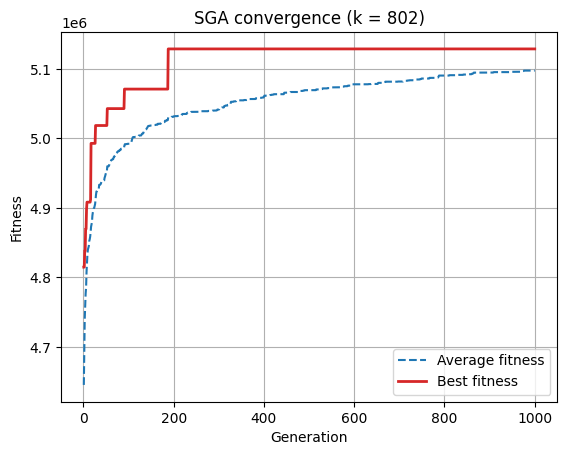

Test with k = 400
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 3,425,933.00
Best fitness of final population:    3,445,924
Number of items (best individual):   400
Average value per selected item:     8,614.81
Optimum for k = 400: 4,682,804 (73.59% reached)
All individuals have exactly k items: True

Test with k = 100
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 1,311,864.77
Best fitness of final population:    1,334,847
Number of items (best individual):   100
Average value per selected item:     13,348.47
Optimum for k = 100: 1,477,370 (90.35% reached)
All individuals have exactly k items: True

Test with k = 10
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 165,903.00
Best fitness of final population:    165,903
Number of items (best individual):   10
Average value per selected item:     16,590.30
Optimum for k = 10: 165,903 (100.00% 

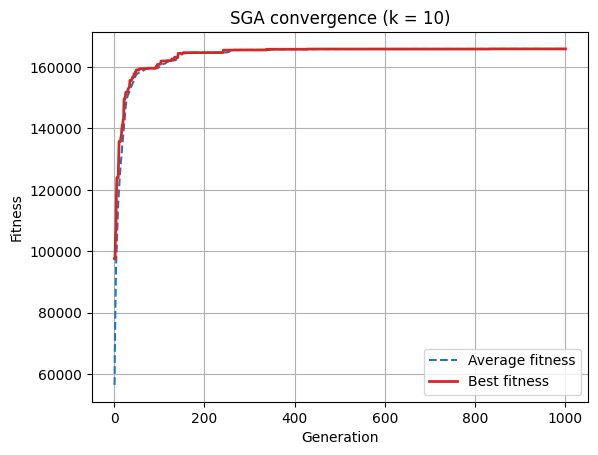

   k  Best fitness  Number of items  Avg value per item  Optimum  % of optimum  Constraint held
1001       5767936             1001             5762.17  5767936        100.00             True
 802       5128897              802             6395.13  6231819         82.30             True
 400       3445924              400             8614.81  4682804         73.59             True
 100       1334847              100            13348.47  1477370         90.35             True
  10        165903               10            16590.30   165903        100.00             True


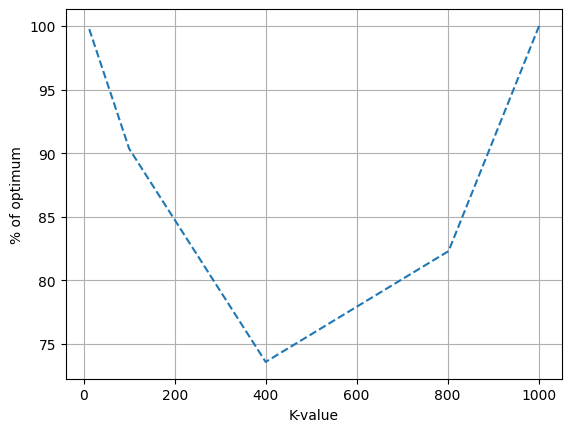

In [16]:
def plot_fitness_data(avg_fitness_data: list[float], best_fitness_data: list[float], k_items: int):
    gens = range(1, len(avg_fitness_data) + 1)

    plt.plot(gens, avg_fitness_data, color="tab:blue", linestyle="--", label="Average fitness")
    plt.plot(gens, best_fitness_data, color="tab:red", linestyle="-", linewidth=2, label="Best fitness")
    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.title(f"SGA convergence (k = {k_items})")
    plt.legend()
    plt.grid(True)
    plt.show()
    
def plot_optimum(results):
    k_values = []
    optimum_values = []
    
    for res in results:
        k_values.append(res["k"])
        optimum_values.append(res["% of optimum"])

    plt.plot(k_values, optimum_values, color="tab:blue", linestyle="--", label="optimum")
    plt.xlabel("K-value")
    plt.ylabel("% of optimum")
    plt.grid(True)
    plt.show()

def test_sga_task_3(k_items: int, pop_size: int = 30, num_iter: int = 500,
                    pc: float = 0.9, pm: float = 0.1, show_plot: bool = False, show_stat: bool = True) -> dict:
    report = simple_genetic_algorithm_task_3(
        population_size=pop_size,
        number_iter=num_iter,
        crossover_prob=pc,
        mutation_prob=pm,
        value_list=item_values,
        k_items=k_items
    )

    avg_fitness_data, best_fitness_data, population, population_fitness = report

    best_index      = np.argmax(population_fitness)
    best_individual = population[best_index]
    best_fitness    = population_fitness[best_index]
    num_items       = sum(best_individual)

    all_exactly_k = all(sum(ind) == k_items for ind in population)

    optimum = np.sort(item_values)[-k_items:].sum()

    if show_stat:
        print("=" * 60)
        print(f"Test with k = {k_items}")
        print(f"Population size: {pop_size} | Iterations: {num_iter} | PC: {pc} | PM: {pm}")
        print(f"Average fitness of final population: {np.mean(population_fitness):,.2f}")
        print(f"Best fitness of final population:    {best_fitness:,}")
        print(f"Number of items (best individual):   {num_items}")
        print(f"Average value per selected item:     {best_fitness / num_items:,.2f}")
        print(f"Optimum for k = {k_items}: {optimum:,} ({best_fitness / optimum * 100:.2f}% reached)")
        print(f"All individuals have exactly k items: {all_exactly_k}")
        print("=" * 60 + "\n")

    if show_plot:
        plot_fitness_data(avg_fitness_data, best_fitness_data, k_items)

    return {
        "k": k_items,
        "Best fitness": best_fitness,
        "Number of items": num_items,
        "Avg value per item": round(best_fitness / num_items, 2),
        "Optimum": optimum,
        "% of optimum": round(best_fitness / optimum * 100, 2),
        "Constraint held": all_exactly_k,
    }, best_individual


k_values = [1001, 802, 400, 100, 10]

results = []
for k in k_values:
    results.append(test_sga_task_3(k, num_iter=1000, show_plot=(k in [802, 10]))[0])

results_table = pd.DataFrame(results)
print(results_table.to_string(index=False))

plot_optimum(results)

#### **% of optimum** reached based on k-values

   k  Best fitness  Number of items  Avg value per item  Optimum  % of optimum  Constraint held
1001       5767936             1001             5762.17  5767936        100.00             True
 800       5025842              800             6282.30  6231752         80.65             True
 750       4868357              750             6491.14  6206310         78.44             True
 700       4580615              700             6543.74  6141437         74.59             True
 600       4108651              600             6847.75  5858323         70.13             True
 500       3730432              500             7460.86  5365267         69.53             True
 450       3407791              450             7572.87  5049330         67.49             True
 400       3146512              400             7866.28  4682804         67.19             True
 350       2869055              350             8197.30  4275830         67.10             True
 300       2591526              300     

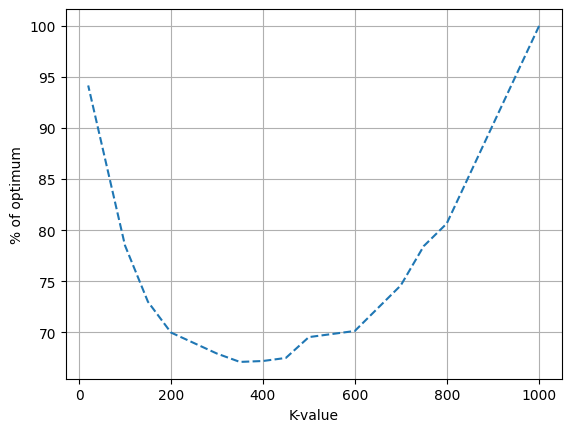

In [19]:
def plot_optimum(results):
    k_values = []
    optimum_values = []
    
    for res in results:
        k_values.append(res["k"])
        optimum_values.append(res["% of optimum"])

    plt.plot(k_values, optimum_values, color="tab:blue", linestyle="--", label="optimum")
    plt.xlabel("K-value")
    plt.ylabel("% of optimum")
    plt.grid(True)
    plt.show()

# 801 - 100
k_values = [1001, 800, 750, 700, 600, 500, 450, 400, 350, 300, 200, 150, 100, 20]

results = []
for k in k_values:
    results.append(test_sga_task_3(k, num_iter=100, show_plot=False, show_stat=False)[0])

results_table = pd.DataFrame(results)
print(results_table.to_string(index=False))
plot_optimum(results)

#### EXTRA CODE STUFF

Test with k = 10
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 165,903.00
Best fitness of final population:    165,903
Number of items (best individual):   10
Average value per selected item:     16,590.30
Optimum for k = 10: 165,903 (100.00% reached)
All individuals have exactly k items: True



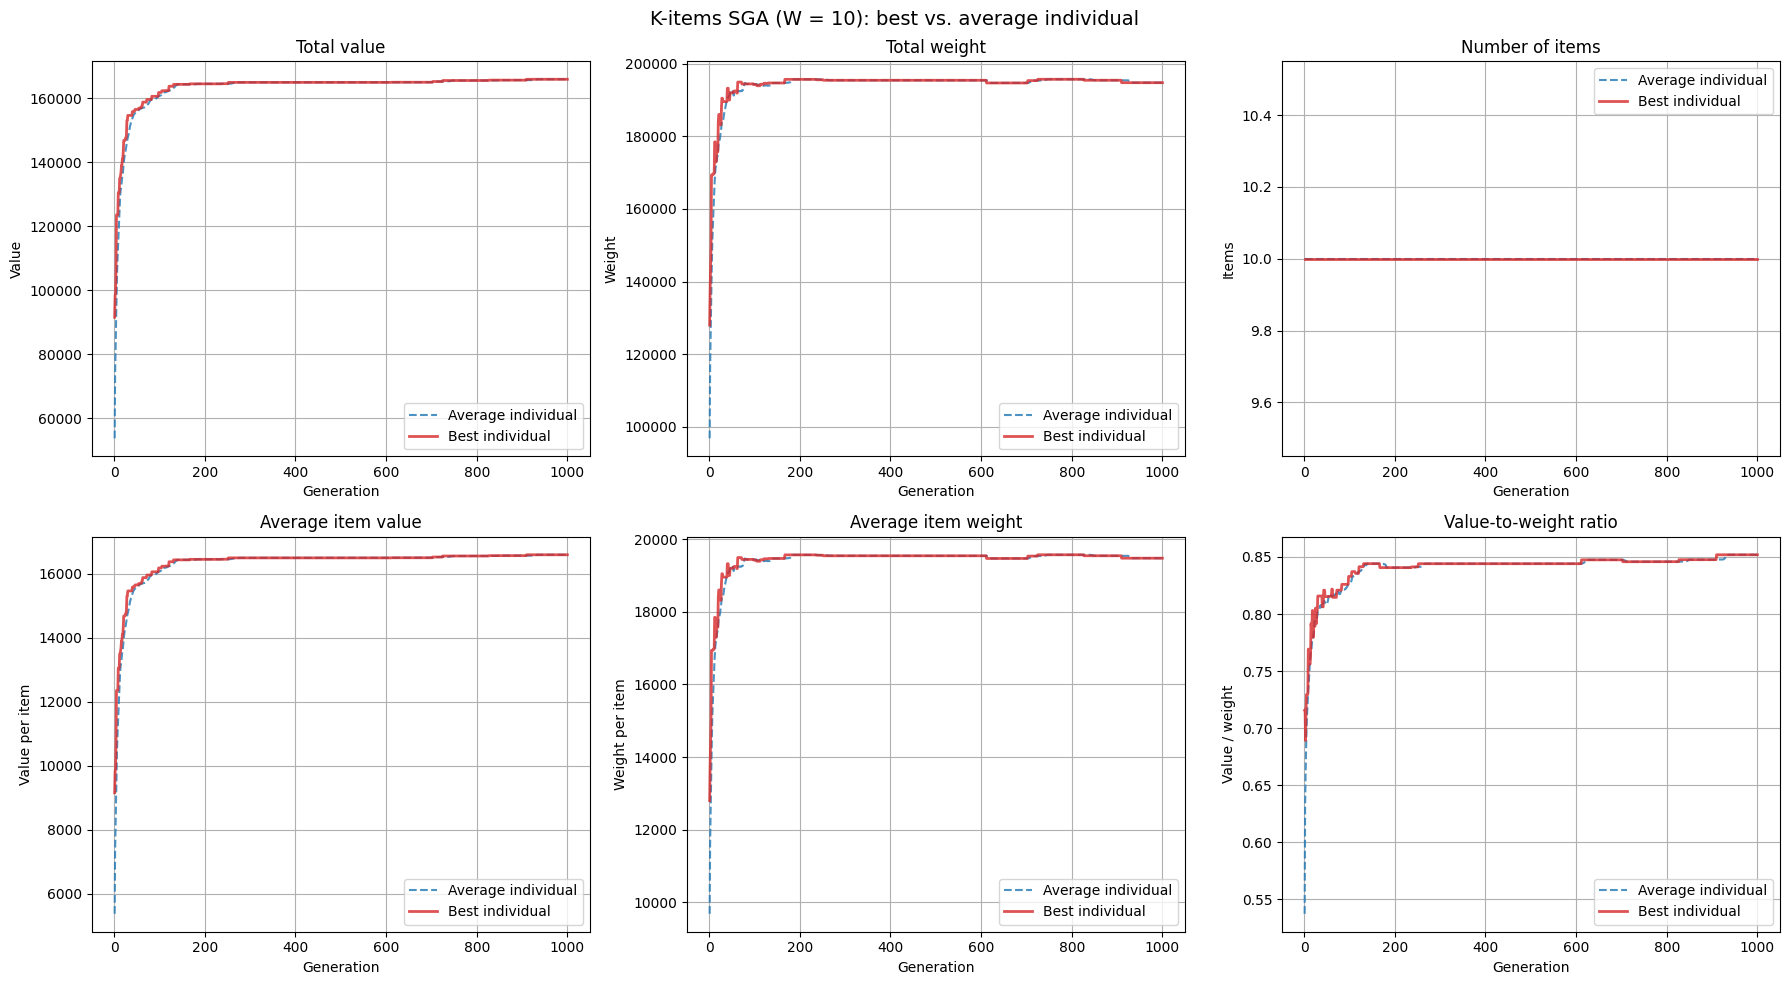

In [20]:
def simple_genetic_algorithm_task_3_extra(
    population_size: int, number_iter: int,
    crossover_prob: float, mutation_prob: float,
    item_values: list, item_weights: list,
    k_items: int
    ):
    """
    SGA for Task 3
    """
    if item_values == None or item_weights == None:
            return
        
    stats = {
        "value": {
            "avg": [],
            "best": []
        },
        "weight": {
            "avg": [],
            "best": []
        },
        "num_items": {
            "avg": [],
            "best": []
        },
        "item_value": {
            "avg": [],
            "best": []
        },
        "item_weight": {
            "avg": [],
            "best": []
        },
        "v_w_ratio": {
            "avg": [],
            "best": []
        },
    }
    
    gene_len = len(item_values)
    population = initialization_knapsack_task_3(
        pop_size=population_size,
        gene_len=gene_len,
        k_items=k_items
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, item_values)

        pop = np.array(population)
        num_items = pop.sum(axis=1)
        num_items[num_items == 0] = 1

        # Get best individual
        best_idx = np.argmax(fitness_values)
        best_individual = pop[best_idx]

        values  = pop @ item_values # total value per individual
        weights = pop @ item_weights # total weight per individual
        counts  = pop.sum(axis=1) # real number of items per individual
        safe    = np.where(counts == 0, 1, counts) # only used for dividing

        per_individual = {
            "value":       values,
            "weight":      weights,
            "num_items":   counts,
            "item_value":  values / safe,
            "item_weight": weights / safe,
            "v_w_ratio":   values / np.where(weights == 0, 1, weights),
        }

        best_idx = np.argmax(fitness_values)
        for name, arr in per_individual.items():
            stats[name]["avg"].append(arr.mean())
            stats[name]["best"].append(arr[best_idx])


        parents = parent_selection_task_3(population, fitness_values)

        offspring = crossover_task_3(parents, crossover_prob, k_items)
        offspring = mutation_task_3(offspring, mutation_prob, k_items)
        offspring_fitness_values = fitness(offspring, item_values)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return population, fitness(population, item_values), stats


def plot_stat_over_generations(ax, avg_data: list[float], best_data: list[float],
                               graph_name: str, y_label: str):
    gens = range(1, len(avg_data) + 1)

    ax.plot(gens, avg_data, color="tab:blue", alpha=0.8, linestyle="--", label="Average individual")
    ax.plot(gens, best_data, color="tab:red", alpha=0.8, linestyle="-", linewidth=2, label="Best individual")
    ax.set_xlabel("Generation")
    ax.set_ylabel(y_label)
    ax.set_title(graph_name)
    ax.legend()
    ax.grid(True)


def test_sga_task_3_extra(k_items: int, pop_size: int = 30, num_iter: int = 500,
                    pc: float = 0.9, pm: float = 0.1, show_plot: bool = False, show_stat: bool = True) -> dict:
    report = simple_genetic_algorithm_task_3_extra(
        population_size=pop_size,
        number_iter=num_iter,
        crossover_prob=pc,
        mutation_prob=pm,
        item_values=item_values,
        item_weights=item_weights,
        k_items=k_items
    )

    population         = report[0]
    population_fitness = report[1]
    stats              = report[2]

    best_index      = np.argmax(population_fitness)
    best_individual = population[best_index]
    best_fitness    = population_fitness[best_index]
    num_items       = sum(best_individual)

    all_exactly_k = all(sum(ind) == k_items for ind in population)
    optimum = np.sort(item_values)[-k_items:].sum()

    best_idx = np.argmax(population_fitness)
    best_individual = population[best_idx]

    final_index = num_iter - 1

    if show_stat:
        print("=" * 60)
        print(f"Test with k = {k_items}")
        print(f"Population size: {pop_size} | Iterations: {num_iter} | PC: {pc} | PM: {pm}")
        print(f"Average fitness of final population: {np.mean(population_fitness):,.2f}")
        print(f"Best fitness of final population:    {best_fitness:,}")
        print(f"Number of items (best individual):   {num_items}")
        print(f"Average value per selected item:     {best_fitness / num_items:,.2f}")
        print(f"Optimum for k = {k_items}: {optimum:,} ({best_fitness / optimum * 100:.2f}% reached)")
        print(f"All individuals have exactly k items: {all_exactly_k}")
        print("=" * 60 + "\n")

    if show_plot:
        plots = [
            ("value",       "Total value",              "Value"),
            ("weight",      "Total weight",             "Weight"),
            ("num_items",   "Number of items",          "Items"),
            ("item_value",  "Average item value",       "Value per item"),
            ("item_weight", "Average item weight",      "Weight per item"),
            ("v_w_ratio",   "Value-to-weight ratio",    "Value / weight"),
        ]

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        for ax, (key, title, y_label) in zip(axes.flat, plots):
            plot_stat_over_generations(ax, stats[key]["avg"], stats[key]["best"], title, y_label)

        fig.suptitle(f"K-items SGA (W = {k_items:,}): best vs. average individual", fontsize=14)
        fig.tight_layout()
        plt.show()

    return stats, best_individual


population_size = 30
number_iter = 1000
crossover_prob = 0.9
mutation_prob = 0.1

report = test_sga_task_3_extra(
    k_items=10,
    pop_size=population_size, num_iter=number_iter,
    pc=crossover_prob, pm=mutation_prob, 
    show_plot=True, show_stat=True
)[1]

### **Commenting on the results**

#### Effect of k on the results

**Results of running with k-items=[1001, 802, 400, 100, 10]:**
| k    | Best    | Items | Val/item | Optimum | % opt  | Valid |
|-----:|--------:|------:|---------:|--------:|-------:|:-----:|
| 1001 | 5767936 | 1001  | 5762.17  | 5767936 | 100.00 | YES   |
| 802  | 4993333 | 802   | 6395.13  | 6231819 | 82.30  | YES   |
| 400  | 2905266 | 400   | 8614.81  | 4682804 | 73.59  | YES   |
| 100  | 977393  | 100   | 13348.47 | 1477370 | 90.35  | YES   |
| 10   | 143231  | 9     | 16590.30 | 165903  | 100.00 | YES   |

In every run, all individuals in the final population had exactly k items, so the updated operators never violated the constraint.

In every run, all individuals in the final population had exactly k items, so the updated operators never violated the constraint.

**Fitness:** The best possible fitness increases with k up to k = 802 and then decreases at k = 1001 (6,231,819 vs. 5,767,936). There are exactly 802 positive-value items, so up to k = 802 every extra slot can hold another positive item, while at k = 1001 the 199 negative-value items are forced into the knapsack and lower the total. The optimum for k = 802 is therefore the same as the unconstrained optimum from Task 2.

**Average value per selected item:** The average value per item decreases steadily as k grows, from 16,591 at k = 10 to 5,762 at k = 1001. With a small k, the knapsack can be filled with only the most valuable items, while each additional slot must be filled with a less valuable one. At k = 1001 every item is selected, so the average equals the mean item value of the data set.

**How close the SGA gets to the optimum:** The SGA reaches the optimum for k = 10 and k = 1001, but only about 74–82% for the larger k values. The k-sweep plot shows the same U-shape: high for small k, lowest around k = 350–450 (≈ 67%), and rising again towards k = 1001 (individual runs vary, which is why the table and plot differ slightly for the same k). We see three reasons:
1. **Search space size:** the number of ways to choose k out of 1001 items is largest around k = 500, so with the same population size and number of generations, the middle range is hardest to search.
2. **Mutation strength:** the expected number of swaps per individual is k × PM, about 1 for k = 10 but about 80 for k = 802, so good solutions with large k are frequently disrupted.
3. **Starting point:** for large k, even a random valid individual reaches a high percentage of the optimum (its expected fitness is about k × 5,762), so part of the high percentage at large k comes "for free". At k = 1001 there is only one valid solution, so crossover and mutation have no effect and 100% is reached trivially.

For small k, random individuals could have a negative total fitness, which broke fitness-proportional parent selection. We fixed this by shifting all fitness values by the minimum fitness before computing selection probabilities.


#### Intresting results from the **k-items** model:
![alt text](../pics_tumi/k_stats_plot.png)


#### Plot of how well k-values capture the **optimum**:
![alt text](../pics_tumi/task3_k-value_optimum.png)


#### **Results of Testing SGA** 
with k-items = [1001, 802, 400, 100, 10], pop_size=30, num_iter=500, cm=0.9, mp=0.1

| k    | Best fitness | Number of items | Avg value per item | Optimum | % of optimum | Constraint held |
|-----:|-------------:|----------------:|-------------------:|--------:|-------------:|:---------------:|
| 1001 | 5767936      | 1001            | 5762.17            | 5767936 | 100.00       | True            |
| 802  | 5144091      | 802             | 6414.08            | 6231819 | 82.55        | True            |
| 400  | 3383245      | 400             | 8458.11            | 4682804 | 72.25        | True            |
| 100  | 1288821      | 100             | 12888.21           | 1477370 | 87.24        | True            |
| 10   | 164911       | 10              | 16491.10           | 165903  | 99.40        | True            |

**Figure:** 3.2.1

#### **Running SGA optimum test** 
with k-items = [800, 750, 700, 600, 500, 450, 400, 350, 300, 200, 150, 100, 20], pop_size=30, num_iter=250, cm=0.9, mp=0.1

![alt text](../pics_tumi/task3_k-value_optimum.png)

**Figure:** 3.2.2

## Subtask 3

Assume now that instead of a constraint for the exact number of items,
there would be a constraint for the upper bound of the number
of items OR a constraint for the upper bound of the summed
weight of selected items in the knapsack (e.g., not more than 100 items
OR not more than 100’000 summed weight of selected items). For both
cases, discuss now (1) which functions would have to be updated and (2)
how each function specifically could be updated so that the constraint is at no point violated.

### Answer to Subtask 3

For both of the constraints, problems arises when we start adding new items to the knapsack. 
With the upper bound adding an item to a knapsack with 100 items would push us over the item limit, and the same with adding a item to the weight limit knapsack can push us past the 100,000 weight limit.

What about removing items from the knapsack? 
With the upper bound removing an item can never push us over the 100 item limit, the same with removing an item from a bag with a weight limit can never push us over the weight limit.

All of the updated functions below expect to be handed a population of indviduals that are not all ready violating the constraints.

So before we go into which functions need to be changed, we can rule out all functions that dont change the knapsack, those functions are: parent selection, survivor selection, and the fitness function.

#### **Constraint 1:** No more than 100 items

**Which functions would have to be updated and why, and how do we update those functions?:** 
##### **Initialization:**
the initialization would not need to be changed since we can just use the same initialization we created for task 3, this would mean all individuals would start with 100 items but that does not break the constraint, another way would be to pick 0-100 random positions in the gene and turn those on.

##### **Crossover:**
for the crossover function we can use the same idea we used to solve it for exactly k-items, but we would need to change the function:
* Group 1 rule: would still be the same, both children pick the items the parents agree on, since the parent will never have more than 100 items we know even if they agree on all items that wont exceed 100 items.
* Group 2 rule is what changes, the original way was splitting the items where only one parent picked that item in half between the kids. The new way to handle group 2 items, we go through group 2 in random order and add items if they still fit.
* Group 3 rule is still the same we ignore all items that neither parent picked.
  
##### **Mutation:**
for the mutation function we can again reuse the function we created for task 3, that mutation function works by going throught each selected item in the knapsack, and with probability **PM**, mutates it: the item is removed, and a randomly chosen unselected item is added in its place. But we would change two things:
* When a selected item mutates it gets removed but not replaced.
* After going through the selected items, we take the inital number of selcted items - 100, and then select that many random chosen unselcted items, then for each item we give it a "PM" chance of being selected.
After these changes we guarantee that the number of items never exceeds 100.


#### **Constraint 2:** Sum of item weight <= 100,000
**Which functions would have to be updated and why, and how do we update those functions?:**

##### **Initialization:**
The initialization function needs to be changed, We will be basing this of the initialization function in Task 2 since how it works currently: the input is population size and number of bits (size of knapsack/number of items), then the function goes through each item and gives it a 50/50 chance of being selected, this does not guarantee a weight of under 100,000. 

So how do we update the function to guarantee a weight of under 100,000 to comply with the constraint? Our solution:
1. Create the knapsack with no items selected, plus a weight_total variable set to 0.
2. Select a random item from the unselected items in the knapsack.
3. check if the weight of the selected item plus the total weight of the knapsack is less than 100,000 then continue to *step 4*, if the weight is over 100,000 return the knapsack without the selected item.
4. Add the selected item to the knapsack, add the weight of the selected item to weight_total.
5. Repeat from *step 2*.

This guarantees that the weight of the knapsack never exceeds 100,000.

##### **Crossover:**
the crossover function needs to be change, since we cant guarantee that if we split both the parent at a random point that each half is eaxactly 50%, and this will break the weight constraint if two knapsacks that are full dont get split exactly 50% weight in both halfs.

So how do we update the crossover function to guarantee a weight of under 100,000? Our solution:
We will use the same solution we used in Task 3, splitting each item into three groups: 
1. *Group 1:* Items both parents selected.
2. *Group 2:* Items exactly one parent selected.
3. *Group 3:* Items neither parent selected.

Then we move on to creating the children:
1. Both children select all items from group 1.
2. We do this for both children. Go through group 2 in random order. For each item, if the child's current weight plus that items weight is less than 100,000 select that item, otherwise skip that item.

These changes will make sure that the crossover function never violates the weight constraint.


##### **Mutation:**
the mutation function needs to be updated since it removes items and adds items. 
So how do we update the mutation function to guarantee a weight of under 100,000? 
We can use the same idea as in the mutation function in task 1, where we give each item in the knapsack probability of *PM* to mutate.
When the item mutates there are two possible scenarios:
1. Selected to unselected (1 -> 0): here there is no special check we need to make since we are removing an item, which always decreases the weight.
2. Unselected to selected (0 -> 1): since we are adding an item to the knapsack we have to make sure that the items weight plus the knapsacks weight does not exceed 100,000. if the total weight is under 100,000 we select that item, Otherwise we move on to the next item in the knapsack.



## Subtask 4

BONUS (10 points): Implement a new version of the SGA for one of
the two problems (Task 3, subtask 3). Discuss with reference to the best
result from the SGA with the exact number of items constraint (Task 3,
subtask 1 & subtask 2), how the solution found is different (e.g., in terms
of the summed weight or the number of items found) and briefly explain
why the result may be better or worse.

**Weight limit 100,000 constraint**

### Code

#### SETUP

In [21]:
item_weights = df["Weight"].to_list()
WEIGHT_LIMIT = 100000

In [22]:
def test_weight(population: list, item_weights: list, print_each=True):
    weights = np.array(item_weights)
    passes = 0
    pop_size = len(population)

    print("Weight Constraint check =============")
    for individual in population: 
        individual = np.array(individual)
        weight = np.dot(individual, weights)

        if print_each == True:
            status = "UNDER LIMIT" if weight <= WEIGHT_LIMIT else "OVER LIMIT"
            print(f"{status} | weight = {weight}")
        passes += 1 if weight <= WEIGHT_LIMIT else 0
    
    print(f"{passes}/{pop_size} Within constraint of {WEIGHT_LIMIT}")
    print("=====================================\n")
    

#### Initialization

In [23]:
def initialization_weight( pop_size: int, gene_len: int, weight_lim: int, item_weights: list[int]) -> list[list[int]]:    
    population = []

    for _ in range(pop_size):
        total_weight = 0
        individual = np.zeros(gene_len, dtype=int)

        for index in np.random.permutation(gene_len):
            total_weight += item_weights[index]
            if total_weight <= weight_lim:
                individual[index] = 1
            else:
                break
        
        population.append(individual.tolist())
    
    return population

In [24]:
pop = initialization_weight(50, len(item_values), WEIGHT_LIMIT, item_weights)

#test_structure(pop)

#### Crossover

In [25]:
def make_children_weight(parent_a: list[int], parent_b: list[int], item_weights) -> tuple[list[int], list[int]]:
    #build child
    arr_a = np.array(parent_a)
    arr_b = np.array(parent_b)
    weights = np.array(item_weights)

    group_1 = (arr_a == 1) & (arr_a == 1)
    group_2 = (arr_a == 1) ^ (arr_a == 1)
    group_2_positions = np.where(group_2)[0]

    children = []
    for _ in range(2):
        child = np.zeros(len(parent_a), dtype=int)
        child[group_1] = 1
        child_weight = weights[group_1].sum()

        for position in np.random.permutation(group_2_positions):
            if child_weight + weights[position] <= WEIGHT_LIMIT:
                child[position] = 1
                child_weight += weights[position]

        children.append(child.tolist())

    return children[0], children[1]


def crossover_weight( parents: list[list[int]], crossover_prob: float, item_weight: list[int], weight_lim) -> list[list[int]]:
    offspring = []

    for i in range(0, len(parents) - 1, 2):
        parent_a, parent_b = parents[i], parents[i + 1]

        if np.random.uniform(0, 1) <= crossover_prob:
            child_1, child_2 = make_children_weight(parent_a, parent_b, item_weights)
        else:
            child_1, child_2 = parent_a.copy(), parent_b.copy()

        offspring.append(child_1)
        offspring.append(child_2)

    if len(parents) % 2 == 1:
        offspring.append(parents[-1].copy())

    return offspring


In [26]:
pop = initialization_weight(15, len(item_values), WEIGHT_LIMIT, item_weights)
#test_structure(pop)
test_weight(pop, item_weights)

pop = crossover_weight(pop, 0.9, item_weights, WEIGHT_LIMIT)
#test_structure(pop)
test_weight(pop, item_weights)

#plot_value_against_weight(pop, item_values, item_weights)

#plot_avg_value_against_weight(pop, item_values, item_weights)

#plot_generation_avg_value_vs_weight([pop], item_values, item_weights)


Weight Constraint check =============
UNDER LIMIT | weight = 96570
UNDER LIMIT | weight = 96566
UNDER LIMIT | weight = 94650
UNDER LIMIT | weight = 83776
UNDER LIMIT | weight = 94342
UNDER LIMIT | weight = 86014
UNDER LIMIT | weight = 93311
UNDER LIMIT | weight = 91725
UNDER LIMIT | weight = 97953
UNDER LIMIT | weight = 96842
UNDER LIMIT | weight = 95507
UNDER LIMIT | weight = 94886
UNDER LIMIT | weight = 96695
UNDER LIMIT | weight = 86455
UNDER LIMIT | weight = 99732
15/15 Within constraint of 100000

Weight Constraint check =============
UNDER LIMIT | weight = 96570
UNDER LIMIT | weight = 96570
UNDER LIMIT | weight = 94650
UNDER LIMIT | weight = 94650
UNDER LIMIT | weight = 94342
UNDER LIMIT | weight = 94342
UNDER LIMIT | weight = 93311
UNDER LIMIT | weight = 93311
UNDER LIMIT | weight = 97953
UNDER LIMIT | weight = 97953
UNDER LIMIT | weight = 95507
UNDER LIMIT | weight = 95507
UNDER LIMIT | weight = 96695
UNDER LIMIT | weight = 96695
UNDER LIMIT | weight = 99732
15/15 Within constr

#### Mutation

In [27]:
def mutation_weight( individuals: list[list[int]], mutation_prob: float, item_weights: list[int], weight_lim: int) -> list[list[int]]:
    """ meow """
    mutated = []

    for individual in individuals:
        offspring = individual.copy()
        weight = np.dot(offspring, item_weights)

        mask = np.random.rand(len(offspring)) < mutation_prob
        hits = np.where(mask == 1)[0]

        indexes = np.random.permutation(hits)

        for index in indexes:
            if offspring[index] == 1:
                # 1 -> 0
                weight -= item_weights[index]
                offspring[index] = 0
            elif (weight + item_weights[index]) <= weight_lim:
                # 0 -> 1
                weight += item_weights[index]
                offspring[index] = 1

        mutated.append(offspring)

    return mutated

In [28]:
pop = initialization_weight(15, len(item_values), WEIGHT_LIMIT, item_weights)

#test_structure(pop)
test_weight(pop, item_weights, print_each=False)
#plot_avg_value_against_weight(pop, item_values, item_weights)

pop = mutation_weight(pop, mutation_prob=0.1, item_weights=item_weights, weight_lim=WEIGHT_LIMIT)

#test_structure(pop)
test_weight(pop, item_weights, print_each=False)
#plot_avg_value_against_weight(pop, item_values, item_weights)

#plot_generation_avg_value_vs_weight([pop], item_values, item_weights)

Weight Constraint check =============
15/15 Within constraint of 100000

Weight Constraint check =============
15/15 Within constraint of 100000



#### SGA

In [29]:
def simple_genetic_algorithm_weights(
    population_size: int, number_iter: int,
    crossover_prob: float, mutation_prob: float,
    item_values: list, item_weights: list, weight_limit: int):
    """
    SGA for bonus task
    """
    if item_values == None or item_weights == None:
        return
    

    stats = {
        "value": {
            "avg": [],
            "best": []
        },
        "weight": {
            "avg": [],
            "best": []
        },
        "num_items": {
            "avg": [],
            "best": []
        },
        "item_value": {
            "avg": [],
            "best": []
        },
        "item_weight": {
            "avg": [],
            "best": []
        },
        "v_w_ratio": {
            "avg": [],
            "best": []
        },
    }
    
    gene_len = len(item_values)
    population = initialization_weight(
        pop_size=population_size,
        gene_len=gene_len,
        item_weights=item_weights,
        weight_lim=weight_limit
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, item_values)

        pop = np.array(population)
        num_items = pop.sum(axis=1)
        num_items[num_items == 0] = 1

        # Get best individual
        best_idx = np.argmax(fitness_values)
        best_individual = pop[best_idx]

        values  = pop @ item_values # total value per individual
        weights = pop @ item_weights # total weight per individual
        counts  = pop.sum(axis=1) # real number of items per individual
        safe    = np.where(counts == 0, 1, counts) # only used for dividing

        per_individual = {
            "value":       values,
            "weight":      weights,
            "num_items":   counts,
            "item_value":  values / safe,
            "item_weight": weights / safe,
            "v_w_ratio":   values / np.where(weights == 0, 1, weights),
        }

        best_idx = np.argmax(fitness_values)
        for name, arr in per_individual.items():
            stats[name]["avg"].append(arr.mean())
            stats[name]["best"].append(arr[best_idx])
    

        parents = parent_selection_task_3(population, fitness_values)

        offspring = crossover_weight(parents, crossover_prob, item_weights, weight_limit)
        offspring = mutation_weight(offspring, mutation_prob, item_weights, weight_limit)
        offspring_fitness_values = fitness(offspring, item_values)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return population, fitness(population, item_values), stats

#### helper

In [30]:
def plot_gen_avg(values: list, weights: list):
    arr_values = np.array(values)
    arr_weights = np.array(weights)

    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    colors = plt.cm.tab20(np.linspace(0, 1, len(arr_values)))

    plt.figure(figsize=(10, 7))
    for i in range(len(arr_values)):
        plt.scatter(
            arr_values[i], arr_weights[i],
            s=10, alpha=0.6,
            color=colors[i],
            marker=markers[i % len(markers)],
            label=f"Generation {i}"
        )

    plt.xlabel("Avg item weight")
    plt.ylabel("Avg item value")
    plt.title("Average item value vs average Item weight for each generation")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.show()


def plot_stat_over_generations(
        avg_data: list[float], 
        best_data: list[float], 
        graph_name: str = "MISSING",
        y_label: str = "MISSING",
        ):
    gens = range(1, len(avg_data) + 1)

    plt.plot(gens, avg_data, color="tab:blue", alpha=0.8, linestyle="--", label="Average Individual")
    plt.plot(gens, best_data, color="tab:red", alpha=0.8, linestyle="-", linewidth=2, label="Best Individual")
    plt.xlabel("Generation")
    plt.ylabel(y_label)
    plt.title(graph_name)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_average_over_generations(
                avg_data: list[float],
                graph_name: str = "MISSING",
                y_label: str = "MISSING"):
    gens = range(1, len(avg_data) + 1)

    plt.plot(gens, avg_data, color="tab:blue", linestyle="--", label="Average entry")
    plt.xlabel("Generation")
    plt.ylabel(y_label)
    plt.title(graph_name)
    plt.legend()
    plt.grid(True)
    plt.show()

#### Testing the weight SGA

Test with weight limit = 100000
Population size: 30 | Iterations: 1000 | PC: 0.9 | PM: 0.1
Average fitness of final population: 78,345.00
Best individual
Best value: 78,345
Best sum of weight: 99,647
Number of items: 7
Average value per selected item: 11,192.14
Average weight per selected item: 14,235.29



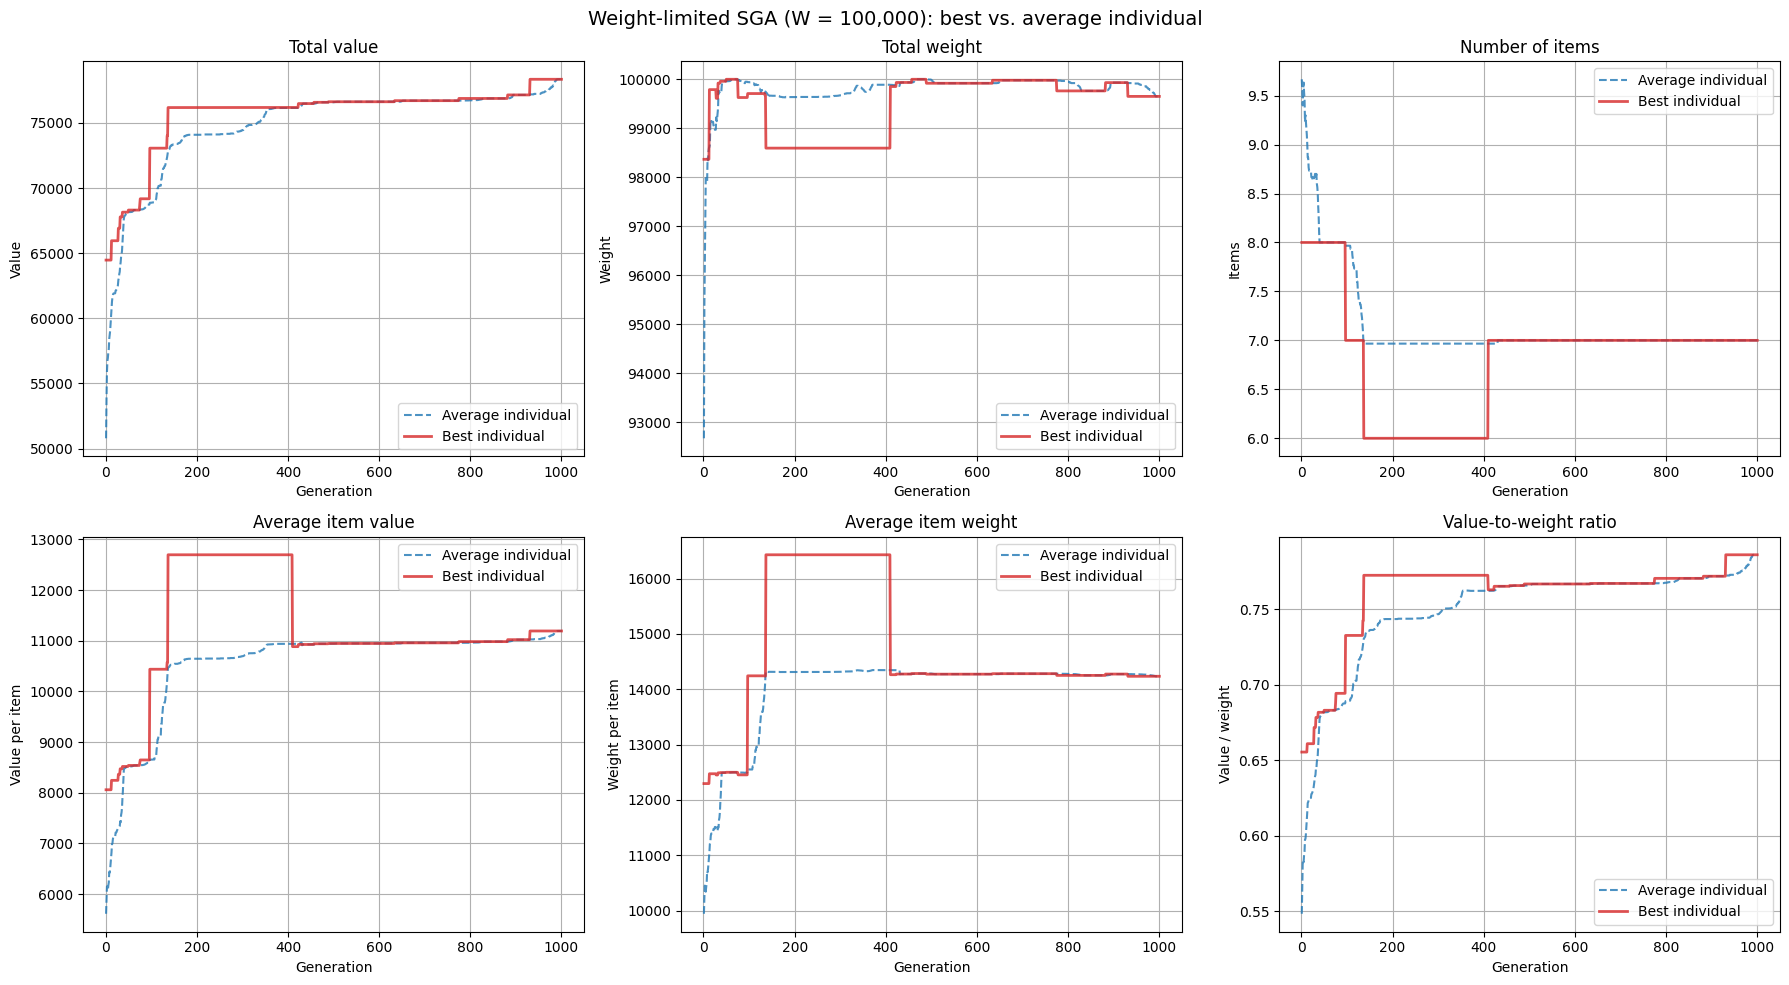

In [31]:
def plot_stat_over_generations(ax, avg_data: list[float], best_data: list[float],
                               graph_name: str, y_label: str):
    gens = range(1, len(avg_data) + 1)

    ax.plot(gens, avg_data, color="tab:blue", alpha=0.8, linestyle="--", label="Average individual")
    ax.plot(gens, best_data, color="tab:red", alpha=0.8, linestyle="-", linewidth=2, label="Best individual")
    ax.set_xlabel("Generation")
    ax.set_ylabel(y_label)
    ax.set_title(graph_name)
    ax.legend()
    ax.grid(True)


def test_sga_weight(
            pop_size: int = 30, num_iter: int = 500,
            pc: float = 0.9, pm: float = 0.1,
            item_values: list = None, item_weights: list = None,
            weight_limit: int = WEIGHT_LIMIT,
            show_plot: bool = False, show_stat: bool = True) -> dict:
    """
    function to test the weight SGA
    """
    report = simple_genetic_algorithm_weights(
        population_size=pop_size,
        number_iter=num_iter,
        crossover_prob=pc,
        mutation_prob=pm,
        item_values=item_values,
        item_weights=item_weights,
        weight_limit=weight_limit
    )

    population         = report[0]
    population_fitness = report[1]
    stats              = report[2]

    best_idx = np.argmax(population_fitness)
    best_individual = population[best_idx]

    final_index = num_iter - 1

    if show_stat:
        print("=" * 60)
        print(f"Test with weight limit = {weight_limit}")
        print(f"Population size: {pop_size} | Iterations: {num_iter} | PC: {pc} | PM: {pm}")
        print(f"Average fitness of final population: {np.mean(population_fitness):,.2f}")
        print(f"Best individual")
        print(f"Best value: {stats["value"]["best"][final_index]:,}")
        print(f"Best sum of weight: {stats["weight"]["best"][final_index]:,}")
        print(f"Number of items: {stats["num_items"]["best"][final_index]}")
        print(f"Average value per selected item: {stats["value"]["best"][final_index] / stats["num_items"]["best"][final_index]:,.2f}")
        print(f"Average weight per selected item: {stats["weight"]["best"][final_index] / stats["num_items"]["best"][final_index]:,.2f}")
        print("=" * 60 + "\n")
        
        #test_weight(population, item_weights, print_each=False)

        if show_plot:
            plots = [
                ("value",       "Total value",              "Value"),
                ("weight",      "Total weight",             "Weight"),
                ("num_items",   "Number of items",          "Items"),
                ("item_value",  "Average item value",       "Value per item"),
                ("item_weight", "Average item weight",      "Weight per item"),
                ("v_w_ratio",   "Value-to-weight ratio",    "Value / weight"),
            ]

            fig, axes = plt.subplots(2, 3, figsize=(18, 10))
            for ax, (key, title, y_label) in zip(axes.flat, plots):
                plot_stat_over_generations(ax, stats[key]["avg"], stats[key]["best"], title, y_label)

            fig.suptitle(f"Weight-limited SGA (W = {weight_limit:,}): best vs. average individual", fontsize=14)
            fig.tight_layout()
            plt.show()
    
    return stats, best_individual


population_size = 30
number_iter = 1000
crossover_prob = 0.9
mutation_prob = 0.1

report = test_sga_weight(
    population_size, number_iter,
    crossover_prob, mutation_prob,
    item_values, item_weights, 
    WEIGHT_LIMIT, 
    show_plot=True, show_stat=True
)


#### Testing SGA from Task 3.2 and 3.4

In [ ]:
print("K-exactly SGA test")
k = 10

best_individual_1 = test_sga_task_3(
    k, 
    pop_size=30,
    num_iter=1000,
    show_plot=False,
    show_stat=False)[1]

total_value_1 = np.array(best_individual_1) @ np.array(item_values)
total_weight_1 = np.array(best_individual_1) @ np.array(item_weights)
print(f"K-value: {k}")
print(f"Total Value: {total_value_1}")
print(f"Total weight: {total_weight_1}")
print(f"Value-to-Weight ratio: {total_value_1/total_weight_1:.2f}")

print(f"\n|={"-"*50}=|\n")

print("Weight SGA test")
best_individual_2 = test_sga_weight(
    item_values=item_values, item_weights=item_weights,
    pop_size=30,
    num_iter=1000,
    weight_limit=WEIGHT_LIMIT, 
    show_plot=False, show_stat=False)[1]

total_value_2 = np.array(best_individual_2) @ np.array(item_values)
total_weight_2 = np.array(best_individual_2) @ np.array(item_weights)
print(f"Weight limit: {WEIGHT_LIMIT}")
print(f"Total Value: {total_value_2}")
print(f"Total weight: {total_weight_2}")
print(f"Value-to-Weight ratio: {total_value_2/total_weight_2:.2f}")


### Writen answer

How the best solution is found for both models:
* **K items:** Here we will be using the % of the optimum reached as our measure of how well a model has performed, and k = 10 reached the best at 99%.
* **Weight limit:** Here it is a bit easier since the algortihm spits out one single individual, so that individual is the best.


#### Results from running the 2 models


##### Comparison with the exact-k constraint
We compare the weight-limited SGA (W = 100,000) with the k-items SGA for k = 10, since both end up with a similar, small number of items (10 vs. 7), which makes the comparison more meaningful than against a solution with hundreds of items.

**Results from the two models:** (FROM: Testing SGA from Task 3.2 and 3.4)

**K-items model:** K-value = 10
* Total Value: 164746
* Total weight: 195132
* Value-to-Weight ratio: 0.84
  
**Weight model:** Weight limit = 100000
* Total Value: 78144
* Total weight: 99948
* Value-to-Weight ratio: 0.78
  

**How the solutions differ:** The exact-k solution has no weight limit, so it simply picks (close to) the 10 most valuable items. Because value and weight are strongly correlated in this data set, these are also among the heaviest items (= 19,500 each), giving a total weight of 195,132, almost twice the weight limit. The weight-limited solution has to stay under 100,000, so it fits only 7 lighter items (= 14,300 each) and reaches less than half the total value. The plots show that the weight-limited SGA reaches the limit within the first 50 generations and then stays just below it, using almost the full capacity (99,948).

**Why the result is worse in value:** The weight limit is a much stricter constraint here than k = 10, since the 10 most valuable items alone weigh almost twice the limit, so a lower total value is expected. More interestingly, the weight-limited solution also has a *lower* value-to-weight ratio (0.78 vs. 0.84). In this data set the heaviest items also have the best ratio, so the best use of 100,000 weight would be roughly 5 of the heaviest, most valuable items rather than 7 medium ones. This suggests the SGA did not find the optimum: once it filled the knapsack with 7 items early on (see the number-of-items plot), replacing them with fewer, heavier items requires several coordinated changes at once, which our mutation and crossover rarely produce, since any single addition of a heavy item does not fit in an already full knapsack. The total value was also still slowly increasing at generation 1000, so more generations could improve the result.


#### Intresting results from the **weight** model:
![alt text](../pics_tumi/weight_stats_ploted.png)


#### Intresting results from the **K-items** model:
![alt text](../pics_tumi/k_stats_plot.png)